# 05 · Tuning the policy and putting a value on variety

Phase 4 picked policy F (MMR, then discovery slots for users with narrow feeds, then a streak breaker) at one setting: 35% of users triggered, 2 discovery slots, and the MMR strength matched to arm C. Two questions are left.

1. **Where should the knobs sit?** I sweep three settings: how many users get triggered, how many discovery slots they get, and how hard MMR pushes. Then I look at the trade-off curve between today's relevance and new territory.
2. **Is the variety worth anything?** The offline test only sees one feed page. Phase 2 estimated how a narrower day relates to next-day activity. Here I combine the two into a rough estimate of what F would do to next-day views, with every assumption written out.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.metrics import per_user, paired_bootstrap
from src.fe import feols
from src.daily import user_day_panel, N_TAGS
from src import policies as P

ART = ROOT / "data" / "models"
REP = ROOT / "reports"
FIG = REP / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY, GREEN = "#3b6ea8", "#c0392b", "#8a8a8a", "#2e8b57"

z = np.load(ART / "small_scores.npz")
st = dict(np.load(ART / "user_state.npz"))
truth, Q, ptag, views = z["truth"], z["truth_q"], z["ptag"], z["item_views_big"]
secs = np.expm1(z["log_duration"]) / 1000
S = P.masked(z["lgbm_debiased"], truth)
U = S.shape[0]
lam_star = json.loads((REP / "phase4_results.json").read_text())["mmr_lambda"]
narrow_default = st["narrow"] >= P.NARROW_TRIGGER          # the 35% group from Phase 4, held fixed for comparison

base_top, _ = P.baseline(S)
pu_base = per_user(base_top, Q, truth, ptag, views, secs)
new_base = P.new_to_user(base_top, ptag, st["hist_share"])
print(f"MMR strength from Phase 4: {lam_star:.4f}")

MMR strength from Phase 4: 0.0048


## 1. The sweep

- **Trigger share.** The share of users who get discovery slots, set by moving the narrowness threshold: 0%, 20%, 35% (Phase 4), 50%, 100%.
- **Discovery slots.** 1 to 4 per page of 10.
- **MMR strength.** Off, Phase 4's value, and double and four times that.

Every setting is scored against the same fully observed outcomes. Results are cached in `reports/phase5_sweep.csv`.

In [2]:
SWEEP = REP / "phase5_sweep.csv"
shares = [0.0, 0.2, 0.35, 0.5, 1.0]
lams = [0.0, lam_star, 2 * lam_star, 4 * lam_star]

def run(lam, share, n_slots, mmr_top):
    thr = np.inf if share == 0 else (-np.inf if share == 1 else np.quantile(st["narrow"], 1 - share))
    top, _ = P.mmr_triggered(S, ptag, st, lam, threshold=thr, n_slots=n_slots, base_top=mmr_top)
    pu = per_user(top, Q, truth, ptag, views, secs)
    nt = P.new_to_user(top, ptag, st["hist_share"])
    return {"lam": lam, "share": share, "slots": n_slots,
            "rel_chg_pct": (pu.rel.mean() / pu_base.rel.mean() - 1) * 100,
            "secs_chg_pct": (pu.watch_secs.mean() / pu_base.watch_secs.mean() - 1) * 100,
            "tags": pu.distinct_tags.mean(),
            "new_all": nt.mean(), "new_narrow": nt[narrow_default].mean(),
            "rel_narrow_chg": (pu.rel[narrow_default].mean() / pu_base.rel[narrow_default].mean() - 1) * 100}

done = pd.read_csv(SWEEP) if SWEEP.exists() else pd.DataFrame()
rows = done.to_dict("records")
key = lambda r: (round(r["lam"], 6), r["share"], r["slots"])
have = {key(r) for r in rows}
for lam in lams:
    mmr_top = P.mmr(S, ptag, lam)[0]
    for share in shares:
        for n in ([0] if share == 0 else [1, 2, 3, 4]):
            if (round(lam, 6), share, n) in have:
                continue
            rows.append(run(lam, share, n, mmr_top))
            pd.DataFrame(rows).to_csv(SWEEP, index=False)
sw = pd.DataFrame(rows).sort_values(["lam", "share", "slots"]).reset_index(drop=True)
sw["lam_x"] = (sw.lam / lam_star).round(1)
print(f"{len(sw)} settings")
sw.round(3).head(20)

68 settings


,lam,share,slots,rel_chg_pct,secs_chg_pct,tags,new_all,new_narrow,rel_narrow_chg,lam_x
0,0.000,0.00,0,0.384,0.733,4.070,2.038,2.111,0.718,0.0
1,0.000,0.20,1,0.202,0.526,4.188,2.185,2.527,0.202,0.0
2,0.000,0.20,2,-0.056,0.362,4.321,2.337,2.958,-0.531,0.0
3,0.000,0.20,3,-0.266,0.303,4.468,2.495,3.406,-1.126,0.0
4,0.000,0.20,4,-0.339,0.307,4.600,2.645,3.833,-1.331,0.0
5,0.000,0.35,1,0.186,-0.056,4.281,2.293,2.835,0.156,0.0
6,0.000,0.35,2,-0.277,-0.282,4.502,2.558,3.588,-1.156,0.0
7,0.000,0.35,3,-0.509,-0.235,4.755,2.837,4.378,-1.815,0.0
8,0.000,0.35,4,-0.684,-0.486,4.986,3.101,5.127,-2.312,0.0
9,0.000,0.50,1,0.194,0.052,4.372,2.403,2.839,0.078,0.0


## 2. The trade-off curve

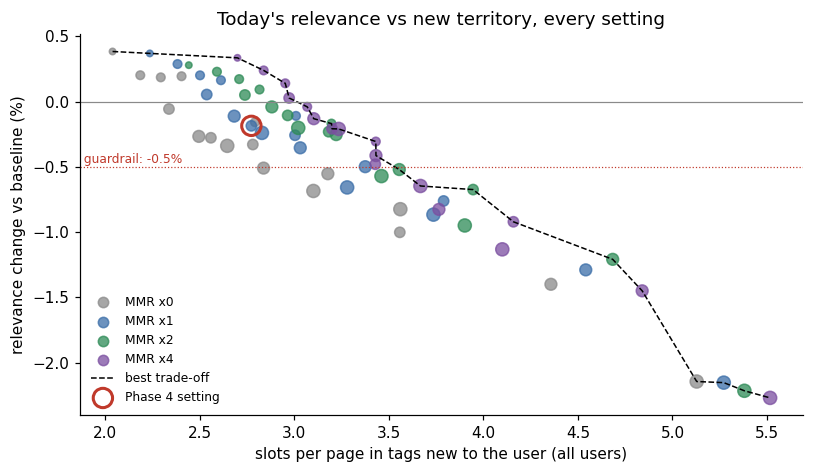

In [3]:
def pareto(d, x="new_all", y="rel_chg_pct"):
    d = d.sort_values(x, ascending=False)
    best, keep = -np.inf, []
    for i, r in d.iterrows():
        if r[y] > best:
            keep.append(i); best = r[y]
    return d.loc[keep].sort_values(x)

front = pareto(sw)
default = sw[(sw.lam_x == 1.0) & (sw.share == 0.35) & (sw.slots == 2)].iloc[0]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
cmap = {0.0: GREY, 1.0: BLUE, 2.0: GREEN, 4.0: "#7b4fa0"}
for lx, g in sw.groupby("lam_x"):
    ax.scatter(g.new_all, g.rel_chg_pct, s=18 + 14 * g.slots, color=cmap.get(lx, GREY), alpha=.75,
               label=f"MMR x{lx:g}")
ax.plot(front.new_all, front.rel_chg_pct, color="black", lw=1, ls="--", label="best trade-off")
ax.scatter([default.new_all], [default.rel_chg_pct], s=160, facecolors="none", edgecolors=RED, lw=2,
           label="Phase 4 setting")
ax.axhline(0, color=GREY, lw=.8)
ax.axhline(-0.5, color=RED, lw=.8, ls=":"); ax.text(ax.get_xlim()[0], -0.47, " guardrail: -0.5%", color=RED, fontsize=8)
ax.set(title="Today's relevance vs new territory, every setting",
       xlabel="slots per page in tags new to the user (all users)", ylabel="relevance change vs baseline (%)")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "05_frontier.png")

Marker size grows with the number of discovery slots. The dashed line joins the settings that no other setting beats on both axes.

In [4]:
g = sw[sw.lam_x == 1.0].pivot_table(index="share", columns="slots", values=["new_all", "rel_chg_pct"])
print("MMR at Phase 4 strength. Rows: share of users triggered. Columns: discovery slots.")
g.round(2)

MMR at Phase 4 strength. Rows: share of users triggered. Columns: discovery slots.


new_all                         rel_chg_pct                        
slots       0     1     2     3     4           0     1     2     3     4
share                                                                    
0.00     2.24   NaN   NaN   NaN   NaN        0.37   NaN   NaN   NaN   NaN
0.20      NaN  2.38  2.54  2.68  2.83         NaN  0.29  0.05 -0.11 -0.24
0.35      NaN  2.50  2.77  3.03  3.28         NaN  0.20 -0.19 -0.35 -0.66
0.50      NaN  2.61  3.00  3.37  3.74         NaN  0.16 -0.26 -0.50 -0.87
1.00      NaN  3.01  3.79  4.54  5.27         NaN -0.11 -0.76 -1.29 -2.15

## 3. Picking the operating point

A sensible rule is to take the setting that adds the most new territory while keeping today's relevance within 0.5% of the baseline. A live test would check that guardrail before anything else.

In [5]:
ok = sw[sw.rel_chg_pct >= -0.5]
pick = ok.sort_values(["new_all", "rel_chg_pct"], ascending=False).iloc[0]
print("Chosen setting")
print(pick.round(3).to_string())
print("\nPhase 4 setting")
print(default.round(3).to_string())

Chosen setting
lam               0.019
share             0.350
slots             3.000
rel_chg_pct      -0.413
secs_chg_pct     -0.452
tags              6.390
new_all           3.432
new_narrow        4.909
rel_narrow_chg   -1.298
lam_x             4.000

Phase 4 setting
lam               0.005
share             0.350
slots             2.000
rel_chg_pct      -0.186
secs_chg_pct      0.219
tags              5.016
new_all           2.773
new_narrow        3.839
rel_narrow_chg   -0.966
lam_x             1.000


In [6]:
thr_pick = np.inf if pick.share == 0 else (-np.inf if pick.share == 1 else np.quantile(st["narrow"], 1 - pick.share))
top_pick, _ = P.mmr_triggered(S, ptag, st, pick.lam, threshold=thr_pick, n_slots=int(pick.slots))
pu_pick = per_user(top_pick, Q, truth, ptag, views, secs)
new_pick = P.new_to_user(top_pick, ptag, st["hist_share"])
ci = {m: paired_bootstrap(pu_base[m], pu_pick[m]) for m in ["rel", "watch_secs", "distinct_tags"]}
ci["new_to_user"] = paired_bootstrap(new_base, new_pick)
pd.DataFrame(ci, index=["diff", "lo", "hi"]).T.round(4)

,diff,lo,hi
rel,-0.0023,-0.0062,0.0015
watch_secs,-0.0385,-0.1901,0.1003
distinct_tags,2.5195,2.4472,2.5882
new_to_user,1.5018,1.4181,1.5812


## 4. What is the variety worth tomorrow?

Phase 2 found that narrower days predict fewer views the next day, comparing equally busy and equally engaging days of the same user. Here I fit the continuous version of that slope, then ask how much the chosen policy would change the narrowness of a user's day.

**Assumptions, stated plainly**
- Each user's day is their last full day in the big matrix (at least 20 views).
- The policy changes that day's tag mix by exactly the difference between its feed page and the baseline's page, scaled by how much of the day is fed by the recommender (`feed_share`). I show 50% and 100%.
- The Phase 2 slope is read as if it were causal. It is not proven to be, so treat the result as an order of magnitude, not a forecast.

In [7]:
from src.features import OUT as FEAT
d = pd.read_parquet(FEAT, columns=["user_id", "day", "ptag", "wr"])
ud = user_day_panel(d)
r = feols(ud, "log_next", ["nar_day", "log_views", "wr_day"], fe=("user_id", "day"))
beta, b_lo, b_hi = r.loc["nar_day", ["coef", "lo", "hi"]]
print(f"Next-day log views per +1.0 of day narrowness: {beta:.3f}  [{b_lo:.3f}, {b_hi:.3f}]   (n = {r.attrs['n']:,} user-days)")
print(f"Spread of day narrowness: 10th pct {ud.nar_day.quantile(.1):.3f}, 90th pct {ud.nar_day.quantile(.9):.3f}")

Next-day log views per +1.0 of day narrowness: -0.320  [-0.441, -0.198]   (n = 140,101 user-days)
Spread of day narrowness: 10th pct 0.213, 90th pct 0.395


In [8]:
users = z["users"]
dd = d[d.user_id.isin(users)]
full_days = dd.groupby(["user_id", "day"]).size()
full_days = full_days[full_days >= 20].reset_index()
last_day = full_days.groupby("user_id").day.max()
dl = dd.merge(last_day.rename("day").reset_index(), on=["user_id", "day"])
cnt = dl.groupby(["user_id", "ptag"]).size().unstack(fill_value=0).reindex(columns=range(N_TAGS), fill_value=0)
p_day = cnt.div(cnt.sum(1), axis=0).reindex(users)
has_day = p_day.notna().all(1).to_numpy()
p_day = p_day.fillna(0).to_numpy()
del d, dd, dl

def nar(p):
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.where(p > 0, p * np.log(p), 0).sum(1)
    return 1 - h / np.log(N_TAGS)

def list_mix(top):
    m = np.zeros((len(top), N_TAGS))
    for u, row in enumerate(top):
        np.add.at(m[u], ptag[row], 1 / len(row))
    return m

shift = list_mix(top_pick) - list_mix(base_top)
val = []
for feed_share in [0.5, 1.0]:
    p_cf = np.clip(p_day + feed_share * shift, 0, None)
    p_cf = p_cf / p_cf.sum(1, keepdims=True)
    dn = (nar(p_cf) - nar(p_day))[has_day]
    trig_pick = (st["narrow"] >= thr_pick)[has_day]
    for grp, mask in [("all users", np.ones_like(trig_pick)), ("triggered users", trig_pick)]:
        x = dn[mask].mean()
        val.append({"feed_share": feed_share, "group": grp, "users": int(mask.sum()),
                    "day_narrowness_change": x,
                    "next_day_views_pct": (np.exp(beta * x) - 1) * 100,
                    "range_lo": (np.exp(b_hi * x) - 1) * 100, "range_hi": (np.exp(b_lo * x) - 1) * 100})
val = pd.DataFrame(val)
val.round(4)

,feed_share,group,users,day_narrowness_change,next_day_views_pct,range_lo,range_hi
0,0.5,all users,1388,-0.0288,0.9237,0.5723,1.2763
1,0.5,triggered users,485,-0.0602,1.9423,1.2011,2.6888
2,1.0,all users,1388,-0.0272,0.8745,0.5419,1.2082
3,1.0,triggered users,485,-0.0682,2.2040,1.3623,3.0527


`range_lo` and `range_hi` come from the 95% interval of the slope. They do not include the uncertainty in the assumptions above, which is larger.

## 5. Today vs tomorrow

In [9]:
v = val[(val.feed_share == 1.0)].set_index("group")
summary = pd.DataFrame({
    "today: relevance": [f"{ci['rel'][0] / pu_base.rel.mean() * 100:+.2f}%  [{ci['rel'][1] / pu_base.rel.mean() * 100:+.2f}, {ci['rel'][2] / pu_base.rel.mean() * 100:+.2f}]"],
    "today: watch seconds": [f"{ci['watch_secs'][0] / pu_base.watch_secs.mean() * 100:+.2f}%  [{ci['watch_secs'][1] / pu_base.watch_secs.mean() * 100:+.2f}, {ci['watch_secs'][2] / pu_base.watch_secs.mean() * 100:+.2f}]"],
    "today: tags per page": [f"{ci['distinct_tags'][0]:+.2f}  ({ci['distinct_tags'][0] / pu_base.distinct_tags.mean() * 100:+.0f}%)"],
    "today: new-territory slots": [f"{ci['new_to_user'][0]:+.2f}  ({ci['new_to_user'][0] / new_base.mean() * 100:+.0f}%)"],
    "tomorrow: views, all users (est.)": [f"{v.loc['all users', 'next_day_views_pct']:+.2f}%  [{v.loc['all users', 'range_lo']:+.2f}, {v.loc['all users', 'range_hi']:+.2f}]"],
    "tomorrow: views, triggered (est.)": [f"{v.loc['triggered users', 'next_day_views_pct']:+.2f}%  [{v.loc['triggered users', 'range_lo']:+.2f}, {v.loc['triggered users', 'range_hi']:+.2f}]"],
}, index=["chosen policy vs baseline"]).T
summary

,chosen policy vs baseline
today: relevance,"-0.41% [-1.10, +0.26]"
today: watch seconds,"-0.45% [-2.23, +1.18]"
today: tags per page,+2.52 (+65%)
today: new-territory slots,+1.50 (+78%)
"tomorrow: views, all users (est.)","+0.87% [+0.54, +1.21]"
"tomorrow: views, triggered (est.)","+2.20% [+1.36, +3.05]"


In [10]:
out = {
    "sweep_settings": int(len(sw)),
    "chosen": {k: (float(pick[k]) if k != "slots" else int(pick[k])) for k in ["lam", "share", "slots", "rel_chg_pct",
                                                                               "secs_chg_pct", "tags", "new_all", "new_narrow"]},
    "phase4_setting": {k: float(default[k]) for k in ["rel_chg_pct", "secs_chg_pct", "tags", "new_all", "new_narrow"]},
    "chosen_ci": {k: [round(float(x), 5) for x in v_] for k, v_ in ci.items()},
    "baseline": {"rel": float(pu_base.rel.mean()), "watch_secs": float(pu_base.watch_secs.mean()),
                 "tags": float(pu_base.distinct_tags.mean()), "new_to_user": float(new_base.mean())},
    "next_day_slope": [round(float(beta), 4), round(float(b_lo), 4), round(float(b_hi), 4)],
    "next_day_estimate": val.round(4).to_dict("records"),
}
(REP / "phase5_results.json").write_text(json.dumps(out, indent=2))
np.save(ART / "phase5_chosen_lists.npy", top_pick)
print("saved")

saved


## Takeaways

1. **The Phase 4 setting was not the best one.** Most of the best trade-off line is made of settings with stronger MMR. Pushing MMR harder is almost free up to about 4x, so variety among familiar tags costs very little. The expensive part is discovery slots.
2. **Trigger share and slot count trade off smoothly.** Giving everyone 4 discovery slots more than doubles new territory but costs about 2% of relevance. Keeping the slots for the 20–35% of users with the narrowest feeds gets most of the benefit for a fraction of the cost. That is the case for targeting.
3. **Chosen setting: MMR at 4x, 35% of users triggered, 3 discovery slots.** Against the baseline, tags per page go from 3.9 to 6.4 (+65%) and new-territory slots rise 78%. Relevance moves −0.4% and watch time −0.5%, and neither change is significant. Triggered users carry most of the cost (about −1.3% relevance for them).
4. **The rough next-day value is positive and bigger for the people it targets.** Read through Phase 2's slope, the policy's change to the daily tag mix works out to about +0.9% next-day views overall and +2.2% for triggered users, with intervals that stay above zero. Halving the share of the day the feed controls barely changes it.
5. **That estimate is the weakest link.** It rests on an observational slope and on the assumption that people watch what they are served in the same mix. It is a reason to run a live test, not a substitute for one.

**What a live test should measure.** The primary metric is next-day and 7-day return for triggered users. Guardrails are session watch time and skip rate on discovery slots. Randomise at the user level, and size the test to detect a 1% change in next-day views.